<a href="https://colab.research.google.com/github/ChayanikaAwasthi/bc-electricity-demand-analysis/blob/main/01_BC_Electricity_Demand_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Project 01: BC Electricity Demand Analysis - 2025**

**1. Introduction**

Electricity deman varies throughout the day and across the year. Understanding these patterns is important for power system planning, grid operations and resource management. This project explores publically available electricity demand data from BC Hydro to identify daily and monthly consumption patterns across British Columbia.

Using Python, Pandas, and Matplotlib, the analysis examines historical electricity demand, identifies peak demand periods, and explores how demand changes over time.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("All libraries imported successfully!")

All libraries imported successfully!


**Project Objectives**
*   Analyze electricity demand patterns across 2025.
*   Identify periods of peak and minimum electricty demand.
*   Examine variations in average demand throughout the day.
*   Explore monthly trends in electricity demand.
*   Build foundational data analysis skills relevant to power systems and grid planning.







**2. Data Source**

The dataset used in this project is publicly available through BC Hydro's Historical Transmission Data webpage.
*   **Source:** BC Hydro
*   **Dataset:** Balancing Authority Load
*   **Data Period:** January 1, 2025 - December 31, 2025
*   **Frequency:** Hourly Observations
*   **Variables:** Date, Hour Ending (HE) and Control Area Load
Source: [BC Hydro - Historical Transmission Data](https://www.bchydro.com/energy-in-bc/operations/transmission/transmission-system/balancing-authority-load-data/historical-transmission-data.html)

**3. Data Loading and Exploration**

The first step is to load the dataset into Python and understand its structure. The Pandas library is used to read and manipulate the Excel datasheet. Initial exploration helps identify the available variables, data types, and overall structure before conducting further analysis.

The following checks are performed:
*   Preview the first few rows of the dataset.
*   Review column names and data types.
*   Identify missing values.
*   Check for duplicate observations.

In [3]:
from google.colab import files
uploaded = files.upload()

Saving BalancingAuthorityLoad 2025.xls to BalancingAuthorityLoad 2025.xls


In [4]:
#identify the uploaded file
file_name = list(uploaded.keys())[0]

#read the excel workbook
excel_file = pd.ExcelFile(file_name)

#display available sheets
print(excel_file.sheet_names)

['HourlyControlAreaLoadReport2025']


In [5]:
df = pd.read_excel(file_name, sheet_name=0)
df.head()

,Hourly Control Area Load Report,Unnamed: 1,Unnamed: 2
0,Date Range:,-2025,NaN
1,Area Group Name:,BCHA,NaN
2,Date,HE,Control Area Load
3,01/01/2025,1,7942
4,01/01/2025,2,7819


In [14]:
df_raw = pd.read_excel(file_name, header =None)
display(df_raw.head(20))

,0,1,2
0,Hourly Control Area Load Report,NaN,NaN
1,Date Range:,-2025,NaN
2,Area Group Name:,BCHA,NaN
3,Date,HE,Control Area Load
4,01/01/2025,1,7942
5,01/01/2025,2,7819
6,01/01/2025,3,7710
7,01/01/2025,4,7637
8,01/01/2025,5,7670
9,01/01/2025,6,7798


In [7]:
df = pd.read_excel(file_name, header = 3)
display(df.head())

,Date,HE,Control Area Load
0,01/01/2025,1,7942
1,01/01/2025,2,7819
2,01/01/2025,3,7710
3,01/01/2025,4,7637
4,01/01/2025,5,7670


**4. Data Cleaning**

Before analyzing the data, the dataset is prepared to ensure that the variables are in an appropriate format.

The preparation process includes:
*   Removing unnecessary whitespace from the column names.
*   Converting the Date column into a datetime format.
*   Checking the date range of the dataset.
*   Reviewing any missing values and duplicates.

In [12]:
df.columns = df.columns.astype(str).str.strip()
print(df['Date'].min())
print(df['Date'].max())

01/01/2025
12/31/2025


In [13]:
#Understanding the size of the dataset (how many roas and columns)
print("Dataset dimensions:", df.shape)

#Inspect Columns
print(df.columns.tolist())

#Check data types
df.info()

#Check missing values
df.isnull().sum()

#Check any duplicates
df.duplicated().sum()


Dataset dimensions: (8760, 3)
['Date', 'HE', 'Control Area Load']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Date               8760 non-null   object
 1   HE                 8760 non-null   object
 2   Control Area Load  8760 non-null   int64 
dtypes: int64(1), object(2)
memory usage: 205.4+ KB


np.int64(0)

**5. Exploratory Data Analysis (EDA)**

Exploratory Data Analysis (EDA) is used to understand the characteristics, patterns, and relationships within a dataset before conducting more advanced analysis. In this section, historical electricity demand data is analyzed to identify overall demand characteristics, monthly variations and daily demand patterns.

  ***5.1 Overall Electricity Demand Statistics***

  The first step is to examine the overall distribution of electricity demand across the available datasets. Descriptive statistics are used to calculate the maximum, minimum and average recorded electricity demand. These values provide an initial understanding of the demand range and help identify period of particular high or low demand.

In [15]:
#Descriptive Statistics
df["Control Area Load"].describe()

,Control Area Load
count,8760.000000
mean,7682.072831
std,1172.922864
min,5359.000000
25%,6896.750000
50%,7570.000000
75%,8475.000000
max,11359.000000


In [16]:
#Find the max demand
max_idx = df["Control Area Load"].idxmax()
peak_demand = df.loc[max_idx]

print(peak_demand)

Date                 02/03/2025
HE                           18
Control Area Load         11359
Name: 809, dtype: object


In [17]:
#Find the min demand
min_idx = df["Control Area Load"].idxmin()
min_demand = df.loc[min_idx]

print(min_demand)

Date                 06/04/2025
HE                            4
Control Area Load          5359
Name: 3698, dtype: object


**Observations**

The initial analysis identified the following characteristics:
*   Maximum recorded demand: 11359 MW, observed on February 03, 2025.
*   Minimum recorded demand: 5359 MW, observed on June 04, 2025.
*   Average recorded demand: approx. 7682 MW.

These results provide an overview of electricity demand across the available dataset and establish a baseline for further analysis.


***5.2 Monthly Average Electricity Demand***

Electricity demand can vary significantly throughout the year due to seasonal changes and other factors. To investigate these variations, the dataset is grouped by month and the average electricity demand is calculated for each month. A line chart is used to visualize monthly demand patterns and identify periods of relatively high and low average demand.



In [18]:
#Monthly Demand Patterns

#Convert the date column into a proper daterime format
df["Date"] = pd.to_datetime(df["Date"])

#Group the data by month and calculate avg electricity demand
monthly_avg = df.groupby(df["Date"].dt.to_period("M"))["Control Area Load"].mean()

print(monthly_avg)

Date
2025-01    8985.081989
2025-02    9117.377976
2025-03    7883.102288
2025-04    7006.637500
2025-05    6807.500000
2025-06    6726.670833
2025-07    7272.799731
2025-08    7200.611559
2025-09    6903.223611
2025-10    7450.202957
2025-11    8102.255201
2025-12    8803.838710
Freq: M, Name: Control Area Load, dtype: float64


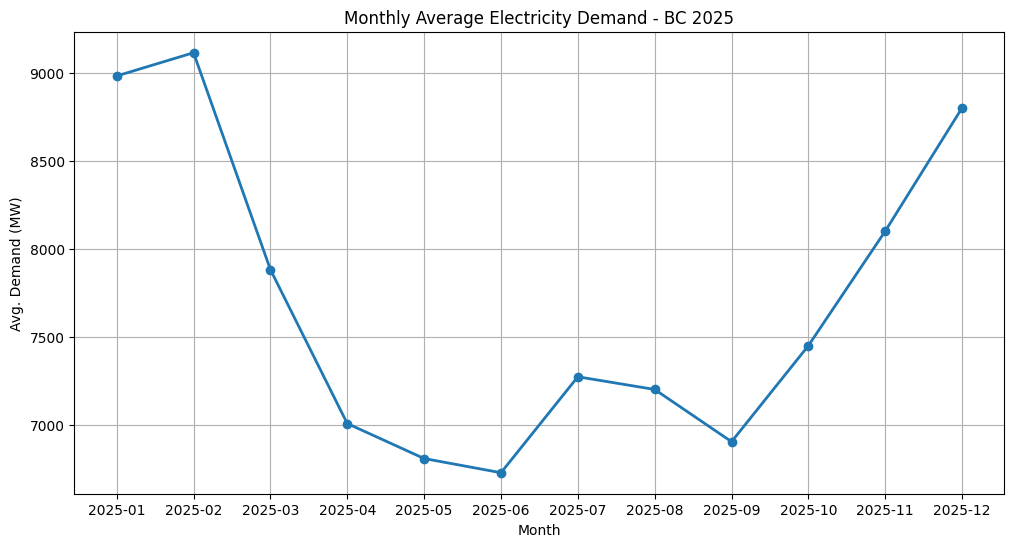

In [20]:
#Visualizing the monthly averages

#Setting the size of the graph
plt.figure(figsize=(12,6))

#Plotting monthly avg. electricty demand
plt.plot(monthly_avg.index.astype(str), monthly_avg.values, marker="o", linewidth=2)

#Adding a title to the graph
plt.title("Monthly Average Electricity Demand - BC 2025")

#Labeling the horizontal and vertical axes
plt.xlabel("Month")
plt.ylabel("Avg. Demand (MW)")

#Adding a grid to make values easier to read
plt.grid(True)

#Displaying the graph
plt.show()

**Observations**

The monthly analysis revealed several patterns:
*   February recorded the highest monthly average demand at approx. 9117 MW.
*   June recorded the lowest monthly average demand at approx. 6726 MW.
*   The average demand increased in July, declined in Septmeber and increased again in October.

The results indicate that electricity demand varies across the months. The decline from February toward June, could be due to weather getting warmer and hence, people may be using less heating. As the daylight hours also increase, consumers may be using less lighting throughout the day.

Further investigation would be needed to determine the exact factors contributing to these changes.

***5.3 Average Electricity Demand by Hour***

Electricty demand also varies throughout the day as residential, commercial and industrial demand changes. To investigate daily demand patterns, the dataset is grouped by Hour Ending (HE), and the average demand is calculated for each hourly interval. This analysis helps identify typical daily demand patterns and the time intevals associated with peak electricity demand.

In [37]:
#Group the observation by Hour Ending (HE)
#Calculate the avg electricity demand for each hour
hourly_df = df.copy()

hourly_df = hourly_df[hourly_df["HE"].astype(str).str.strip()!="2*"]

hourly_avg = hourly_df.groupby("HE")["Control Area Load"].mean()

#Display the avg demand for each hour
print(hourly_avg)

HE
1     6821.958904
2     6644.354396
3     6531.400000
4     6492.621918
5     6550.528767
6     6778.813699
7     7213.454795
8     7734.013699
9     8005.627397
10    8120.397260
11    8165.673973
12    8178.975342
13    8181.843836
14    8149.871233
15    8112.172603
16    8155.906849
17    8337.317808
18    8526.515068
19    8468.367123
20    8343.663014
21    8194.216438
22    7958.780822
23    7548.789041
24    7154.169863
Name: Control Area Load, dtype: float64


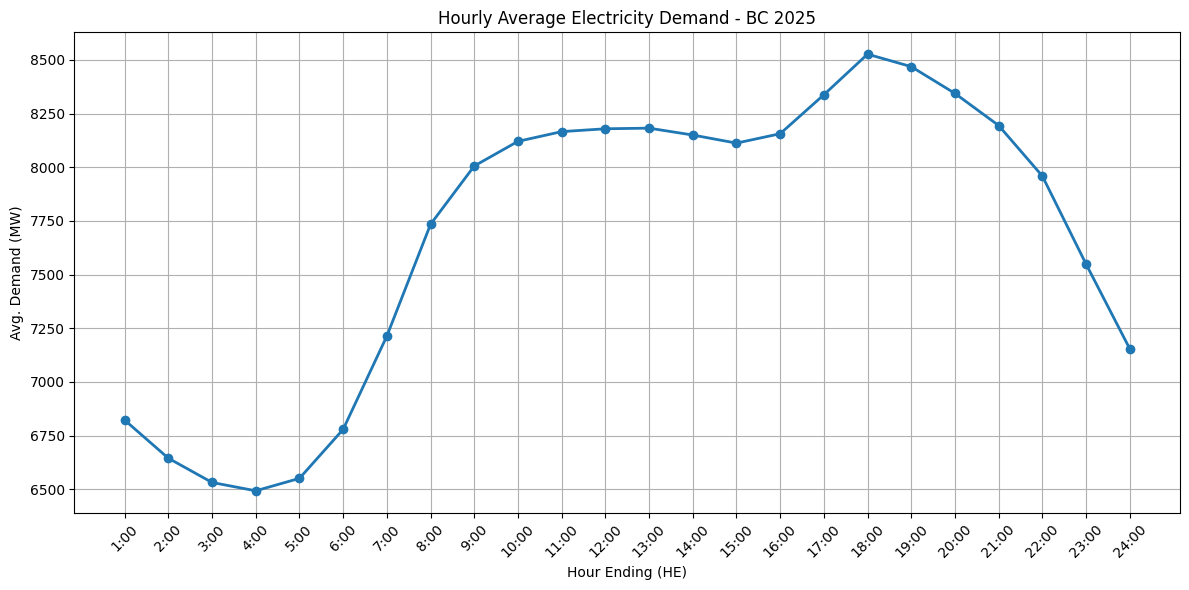

In [42]:
#Visualizing the hourly averages

#Setting the size of the graph
plt.figure(figsize=(12,6))

#Plotting hourly avg. electricty demand
plt.plot(hourly_avg.index, hourly_avg.values, marker="o", linewidth=2)

#Adding a title to the graph
plt.title("Hourly Average Electricity Demand - BC 2025")

#Labeling the horizontal and vertical axes
plt.xlabel("Hour Ending (HE)")
plt.ylabel("Avg. Demand (MW)")

#Create time labels from the hour ending values
hour_labels =[f"{int(hour)}:00" for hour in hourly_avg.index]
# Display all 24 hrs on the x-axis
plt.xticks(hourly_avg.index, hour_labels, rotation =45)

#Adding a grid to make values easier to read
plt.grid(True)

plt.tight_layout()
#Displaying the graph
plt.show()


In [44]:
peak_hour = hourly_avg.idxmax()
peak_value = hourly_avg.max()

print("Peak hour ending:",peak_hour)
print("peak aavg demand:", peak_value,"MW")

Peak hour ending: 18
peak aavg demand: 8526.51506849315 MW


**Observations**

The hourly analysis revealed the following daily demand patterns:
*  Electricity demand begins increasing during the early morning hours, starting at 5:00 AM.
*  Demand fluctuates throughout the afternoon.
*  The highest average demand occurs at HE 6:00 PM.
*  Demand declines following the evening peak.

Identifying daily peak demand periods is important for understanding system loading patterns and supporting system planning and operations.

***5.4 Weekday vs. Weekend Electricity Demand***

Demand patterns may differ between weekdays and weekends due to changes in residential, commercial and industrial activities. This section compares average electricity demand on weekdays and weekends to investigate whether differences in daily consumption patterns can be observed.

In [47]:
#extract the day of the week from the date column
df["Day_of_Week"] = df["Date"].dt.dayofweek

#Classify each day as weekday or weekend
df["Day_Type"] = df["Day_of_Week"].apply(lambda day:"Weekend"if day >= 5 else "Weekday")

#Display the first few rows to check
print(df[["Date", "Day_of_Week", "Day_Type"]].head())

        Date  Day_of_Week Day_Type
0 2025-01-01            2  Weekday
1 2025-01-01            2  Weekday
2 2025-01-01            2  Weekday
3 2025-01-01            2  Weekday
4 2025-01-01            2  Weekday


In [48]:
#Group data by weekday and weekend
#Calculate the average electricity demand for each group
day_type_avg = df.groupby("Day_Type")["Control Area Load"].mean()

#arrange the result in weekday/weekend order
day_type_avg = day_type_avg.reindex(["Weekday", "Weekend"])

#display results
print(day_type_avg)

Day_Type
Weekday    7779.485792
Weekend    7437.603766
Name: Control Area Load, dtype: float64


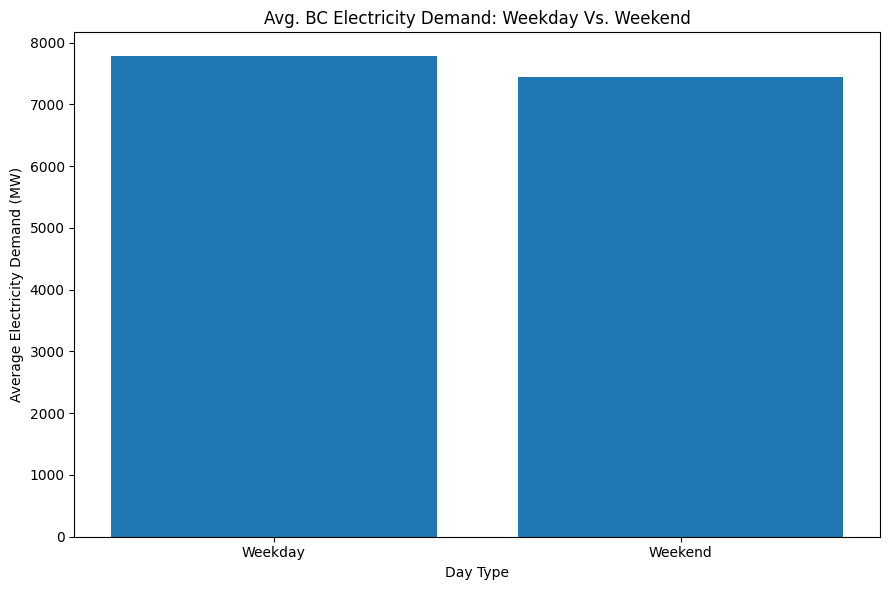

In [54]:
plt.figure(figsize=(9,6))

plt.bar(day_type_avg.index, day_type_avg.values)

plt.title("Avg. BC Electricity Demand: Weekday Vs. Weekend")
plt.xlabel("Day Type")
plt.ylabel("Average Electricity Demand (MW)")

plt.tight_layout()
plt.show()

In [55]:
#Extract the avg. weekday and weekend demand
weekday_avg = day_type_avg["Weekday"]
weekend_avg = day_type_avg["Weekend"]

#Calculate the difference between the two averages
demand_difference = weekend_avg - weekday_avg

percentage_difference = (demand_difference / weekday_avg) * 100

print("Average Weekday Demand:", round(weekday_avg,2))
print("Average Weekend Demand:", round(weekend_avg,2))
print("Demand Difference:", round(demand_difference, 2))
print("Percentage Difference:", round(percentage_difference, 2), "%")

Average Weekday Demand: 7779.49
Average Weekend Demand: 7437.6
Demand Difference: -341.88
Percentage Difference: -4.39 %


**Observation**

The analysis above shows that avg. deman during weekends is approx. 341 MW (4.39%) lower than during weekdays. This pattern is consistent with typical electricity consumption trends observed in power systems. Lower weekend demand may be associated with reduced commercial and industrial activity, as many offices, educational institutions and certain facilities operate on reduced schedules.

Although residential commercial may increase during certain weekend periods, this increase may not fully offset the reduction in commercial and industrial electricity usage.

**6. Conclusion**

This project explored electricity demand patterns in British Columbia using publicly avaialble hourly control area load data from January to December 2025. Using Python and Pandas, the dataset was examined to identify overall demand characteristics and variations across months, hours of the day and days of the week.

From power systems perspective, these insights are relevant to demand forecasting, generation scheduling, resource planning and grid operations. Understanding when and how electricity demand changes helps utilities anticipate system requirements and make informed operational and planning decisions.